# 01 · Carga y diagnóstico de datos

Planta de flotación inversa de hierro (marzo–septiembre 2017). Antes de modelar hay que saber
**con qué frecuencia se mide realmente cada variable**, dónde faltan datos y qué valores no son
mediciones reales (rellenos, interpolaciones, sensores congelados).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

from src.config import DATA_PROCESSED, LEAKY_COLUMNS, SEED, TARGET, TEST_START
from src.evaluation import regression_metrics, relative_improvement
from src.data import hourly_quality_flags, load_raw, runs, time_gaps, to_hourly, unique_per_hour
from src.eda import binned_profile, lagged_spearman
from src.viz import AQUA, BLUE, GRAY, ORANGE, TEXT, save, set_style

set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1. Carga

In [2]:
df = load_raw()
print("Filas x columnas:", df.shape)
print("Rango:", df["date"].min(), "->", df["date"].max())
print("Nulos totales:", int(df.isna().sum().sum()))
print("Timestamps con minutos o segundos != 0:",
      int(((df["date"].dt.minute != 0) | (df["date"].dt.second != 0)).sum()))
df.head(3)

Filas x columnas: (737453, 24)
Rango: 2017-03-10 01:00:00 -> 2017-09-09 23:00:00
Nulos totales: 0
Timestamps con minutos o segundos != 0: 0


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,Flotation Column 03 Air Flow,Flotation Column 04 Air Flow,Flotation Column 05 Air Flow,Flotation Column 06 Air Flow,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,250.576,295.096,306.4,250.225,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,250.862,295.096,306.4,250.137,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,250.313,295.096,306.4,251.345,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31


## 2. Frecuencia real de cada variable

`date` solo tiene resolución horaria: todas las filas de una misma hora comparten timestamp.
Contamos cuántas filas hay por hora y cuántos valores distintos toma cada columna dentro de cada hora.

In [3]:
rows_per_hour = df.groupby("date").size()
rows_per_hour.value_counts().sort_index().rename("n_horas").to_frame()

,n_horas
174,1
179,1
180,4095


In [4]:
uph = unique_per_hour(df).sort_values("unicos_mediana")
uph

,unicos_mediana,unicos_p90,unicos_max,pct_horas_con_1_unico
% Iron Feed,1.0,1.0,1,100.0
% Silica Feed,1.0,1.0,1,100.0
% Iron Concentrate,1.0,1.0,180,94.7
% Silica Concentrate,1.0,1.0,180,92.4
Flotation Column 01 Air Flow,155.0,169.0,180,0.3
Flotation Column 03 Air Flow,163.0,172.0,180,0.3
Flotation Column 04 Air Flow,166.0,180.0,180,11.3
Flotation Column 05 Air Flow,174.0,180.0,180,11.3
Flotation Column 07 Air Flow,174.0,180.0,180,0.3
Flotation Column 06 Air Flow,178.0,180.0,180,0.3


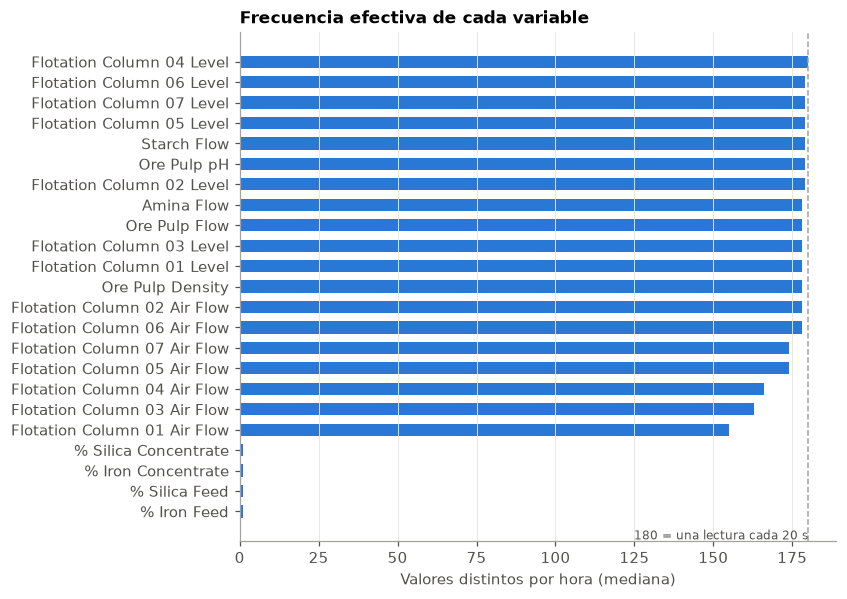

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(uph.index, uph["unicos_mediana"], color=BLUE, height=0.6)
ax.axvline(180, color=GRAY, lw=1, ls="--")
ax.text(180, -1.2, "180 = una lectura cada 20 s", ha="right", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Valores distintos por hora (mediana)")
ax.set_title("Frecuencia efectiva de cada variable")
ax.grid(axis="y", visible=False)
save(fig, "01_unicos_por_hora")
plt.show()

### 2a. Leyes de alimentación (`% Iron Feed`, `% Silica Feed`)

Tienen 1 valor por hora. ¿Cada cuánto cambian, y a qué hora del día?

In [6]:
hourly = df.groupby("date").first()
feed_runs = runs(hourly["% Silica Feed"])
print("Largo de tramos constantes (horas):")
print(feed_runs["n"].value_counts().sort_index().to_string())

Largo de tramos constantes (horas):
n
4        1
5        1
6       92
8        1
9      185
15       9
18       4
24       4
33       1
39       1
48       2
72       1
81       1
192      1
255      1
792      1


In [7]:
change_hours = hourly.index[hourly["% Silica Feed"].diff() != 0].hour
pd.Series(change_hours).value_counts().sort_index().rename("n_cambios").to_frame().T

date,1,7,12,16
n_cambios,106,98,1,101


In [8]:
print("Tramos más largos (probable arrastre del último valor):")
feed_runs.sort_values("n", ascending=False).head(5)

Tramos más largos (probable arrastre del último valor):


,inicio,fin,n,valor
118,2017-05-13 01:00:00,2017-06-15 00:00:00,792,6.26
226,2017-07-24 01:00:00,2017-08-03 15:00:00,255,10.80
234,2017-08-07 01:00:00,2017-08-15 00:00:00,192,25.31
117,2017-05-09 16:00:00,2017-05-13 00:00:00,81,20.24
76,2017-04-21 07:00:00,2017-04-24 06:00:00,72,14.35


### 2b. Target (`% Silica Concentrate`)

Ensayo de laboratorio horario. Revisamos (i) horas donde el valor cambia dentro de la hora y
(ii) horas consecutivas con exactamente el mismo valor.

In [9]:
target_nunique = df.groupby("date")[TARGET].nunique()
interp_hours = target_nunique.index[target_nunique > 1]
print(f"Horas con target variable dentro de la hora: {len(interp_hours)} "
      f"({len(interp_hours) / len(target_nunique):.1%})")

example = df.loc[df["date"] == interp_hours[5], TARGET].to_numpy()
print("Ejemplo", interp_hours[5], "-> primeros valores:", example[:4].round(4))
print("Desv. estándar de los incrementos dentro de la hora:", np.diff(example).std())

Horas con target variable dentro de la hora: 310 (7.6%)
Ejemplo 2017-04-03 02:00:00 -> primeros valores: [3.9215 3.9187 3.916  3.9132]
Desv. estándar de los incrementos dentro de la hora: 4.7581230386404994e-11


In [10]:
target_runs = runs(hourly[TARGET].where(target_nunique == 1))
target_runs = target_runs[target_runs["valor"].notna()]
print("Largo de tramos con el mismo valor horario:")
print(target_runs["n"].value_counts().sort_index().to_string())
target_runs.sort_values("n", ascending=False).head(5)

Largo de tramos con el mismo valor horario:
n
1     3224
2       71
3       20
4        5
5        2
6        5
9        1
10       1
13       2
14       1
15       1
16       2
17       1
19       2
28       1
39       1
73       1


,inicio,fin,n,valor
2820,2017-07-31 20:00:00,2017-08-03 20:00:00,73,2.08
180,2017-03-31 17:00:00,2017-04-02 07:00:00,39,3.11
3116,2017-08-17 02:00:00,2017-08-18 05:00:00,28,1.19
1977,2017-06-21 09:00:00,2017-06-22 03:00:00,19,2.40
1038,2017-05-10 05:00:00,2017-05-10 23:00:00,19,5.03


## 3. Huecos de fechas

In [11]:
gaps = time_gaps(rows_per_hour.index)
gaps

,inicio,fin,horas
0,2017-03-16 06:00:00,2017-03-29 11:00:00,318


In [12]:
print("Horas con menos de 180 filas:")
rows_per_hour[rows_per_hour != 180]

Horas con menos de 180 filas:


date
2017-03-10 01:00:00    174
2017-04-10 00:00:00    179
dtype: int64

## 4. Filas duplicadas y sensores congelados

In [13]:
dup = df.duplicated()
print("Filas duplicadas exactas:", int(dup.sum()))
print("¿Duplicadas también ignorando `date`?", int(df.drop(columns="date").duplicated().sum()))
print("Horas afectadas:", df.loc[dup, "date"].nunique())
df.loc[dup].groupby("date").size().rename("filas_duplicadas").to_frame()

Filas duplicadas exactas: 1171


¿Duplicadas también ignorando `date`? 1171
Horas afectadas: 15


,filas_duplicadas
date,
2017-03-12 01:00:00,1
2017-06-01 15:00:00,5
2017-06-28 15:00:00,14
2017-06-28 16:00:00,84
2017-06-29 14:00:00,10
2017-06-29 15:00:00,16
2017-07-11 06:00:00,81
2017-07-11 07:00:00,179
2017-07-11 08:00:00,179


In [14]:
air_cols = [c for c in df.columns if "Air Flow" in c]
const_air = df.groupby("date")[air_cols].nunique().eq(1)
print("% de horas con aire constante toda la hora, por columna:")
print(const_air.mean().mul(100).round(1).to_string())
runs(const_air["Flotation Column 04 Air Flow"]).query("valor and n > 1")

% de horas con aire constante toda la hora, por columna:
Flotation Column 01 Air Flow     0.3
Flotation Column 02 Air Flow     0.3
Flotation Column 03 Air Flow     0.3
Flotation Column 04 Air Flow    11.3
Flotation Column 05 Air Flow    11.3
Flotation Column 06 Air Flow     0.3
Flotation Column 07 Air Flow     0.3


,inicio,fin,n,valor
0,2017-03-10 01:00:00,2017-04-11 10:00:00,460,True
2,2017-07-11 07:00:00,2017-07-11 09:00:00,3,True


## 5. Banderas de calidad por hora

Se resumen en un `DataFrame` horario que usaremos al construir features.

In [15]:
flags = hourly_quality_flags(df, min_ffill_run=3)
flags["aire_col04_constante"] = const_air["Flotation Column 04 Air Flow"]
flag_cols = ["target_interpolado", "target_repetido", "hora_congelada", "aire_col04_constante"]
summary = flags[flag_cols].agg(["sum", "mean"]).T
summary.columns = ["horas", "fraccion"]
summary["fraccion"] = summary["fraccion"].round(3)
summary

,horas,fraccion
target_interpolado,310.0,0.076
target_repetido,421.0,0.103
hora_congelada,4.0,0.001
aire_col04_constante,465.0,0.113


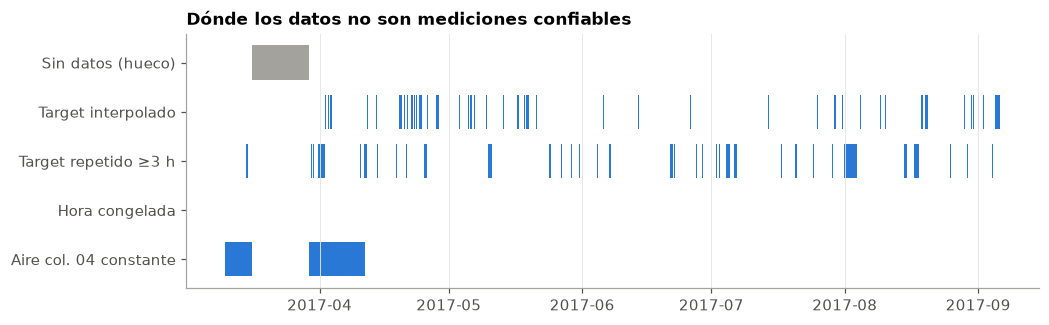

In [16]:
full_index = pd.date_range(flags.index.min(), flags.index.max(), freq="h")
rows = {
    "Sin datos (hueco)": ~full_index.isin(flags.index),
    "Target interpolado": flags["target_interpolado"].reindex(full_index, fill_value=False).to_numpy(),
    "Target repetido ≥3 h": flags["target_repetido"].reindex(full_index, fill_value=False).to_numpy(),
    "Hora congelada": flags["hora_congelada"].reindex(full_index, fill_value=False).to_numpy(),
    "Aire col. 04 constante": flags["aire_col04_constante"].reindex(full_index, fill_value=False).to_numpy(),
}

fig, ax = plt.subplots(figsize=(10, 3))
one_hour = pd.Timedelta("1h")
for i, (label, mask) in enumerate(rows.items()):
    starts = full_index[mask]
    color = GRAY if i == 0 else BLUE
    ax.broken_barh([(s, one_hour) for s in starts], (i - 0.35, 0.7), color=color, lw=0)
ax.set_yticks(range(len(rows)), rows.keys())
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Dónde los datos no son mediciones confiables")
save(fig, "01_calidad_datos_timeline")
plt.show()

---
# Parte 2 · EDA orientada a proceso

Trabajamos a **resolución horaria**, que es la del target: media horaria de cada variable sobre una
grilla regular (el hueco de marzo queda como NaN). El target se usa **solo en horas con ensayo
real**: se excluyen las horas interpoladas, repetidas y congeladas de la sección 5.

In [17]:
hourly = to_hourly(df, flags)
y = hourly[TARGET]
print("Horas en la grilla:", len(hourly), "| horas con target válido:", int(hourly["target_valido"].sum()))

Horas en la grilla: 4415 | horas con target válido: 3362


## 7. El target en el tiempo y su distribución

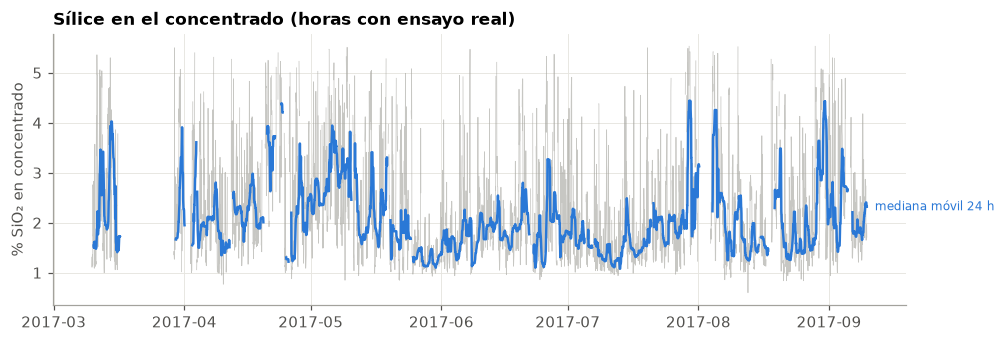

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(y.index, y, color=GRAY, lw=0.5, alpha=0.6)
rolling = y.rolling("24h", min_periods=12).median()
ax.plot(rolling.index, rolling, color=BLUE, lw=1.6)
ax.text(rolling.index[-1], rolling.dropna().iloc[-1], "  mediana móvil 24 h", color=BLUE, va="center", fontsize=8)
ax.set_ylabel("% SiO₂ en concentrado")
ax.set_title("Sílice en el concentrado (horas con ensayo real)")
save(fig, "02_target_serie")
plt.show()

In [19]:
print(y.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_string())
print("Asimetría:", round(y.skew(), 2))
y.resample("MS").agg(["mean", "median", "std", "count"]).round(2)

count    3362.00
mean        2.19
std         1.03
min         0.60
5%          1.07
25%         1.42
50%         1.87
75%         2.67
95%         4.40
max         5.53
Asimetría: 1.19


,mean,median,std,count
date,,,,
2017-03-01,2.55,2.13,1.22,181
2017-04-01,2.43,2.18,1.06,524
2017-05-01,2.30,1.99,1.12,618
2017-06-01,1.99,1.78,0.82,650
2017-07-01,1.95,1.64,0.92,637
2017-08-01,2.15,1.79,1.06,571
2017-09-01,2.41,2.15,1.01,181


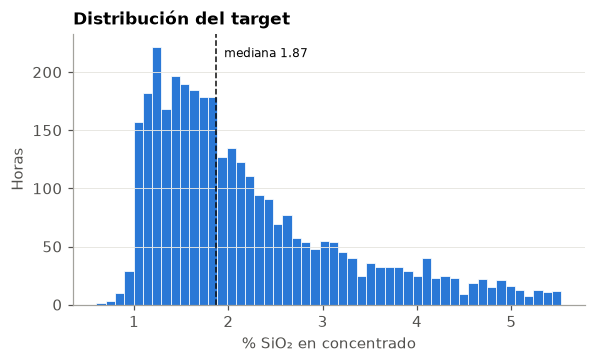

In [20]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(y.dropna(), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(y.median(), color=TEXT, lw=1, ls="--")
ax.text(y.median(), ax.get_ylim()[1] * 0.95, f"  mediana {y.median():.2f}", fontsize=8, va="top")
ax.set_xlabel("% SiO₂ en concentrado")
ax.set_ylabel("Horas")
ax.set_title("Distribución del target")
ax.grid(axis="x", visible=False)
save(fig, "02_target_distribucion")
plt.show()

## 8. Relación del target con las variables de proceso

Nube de puntos horaria (gris) y **mediana del target por decil** de cada variable (azul, con banda
intercuartil). El ρ es la correlación de Spearman (robusta a relaciones monótonas no lineales y a outliers).

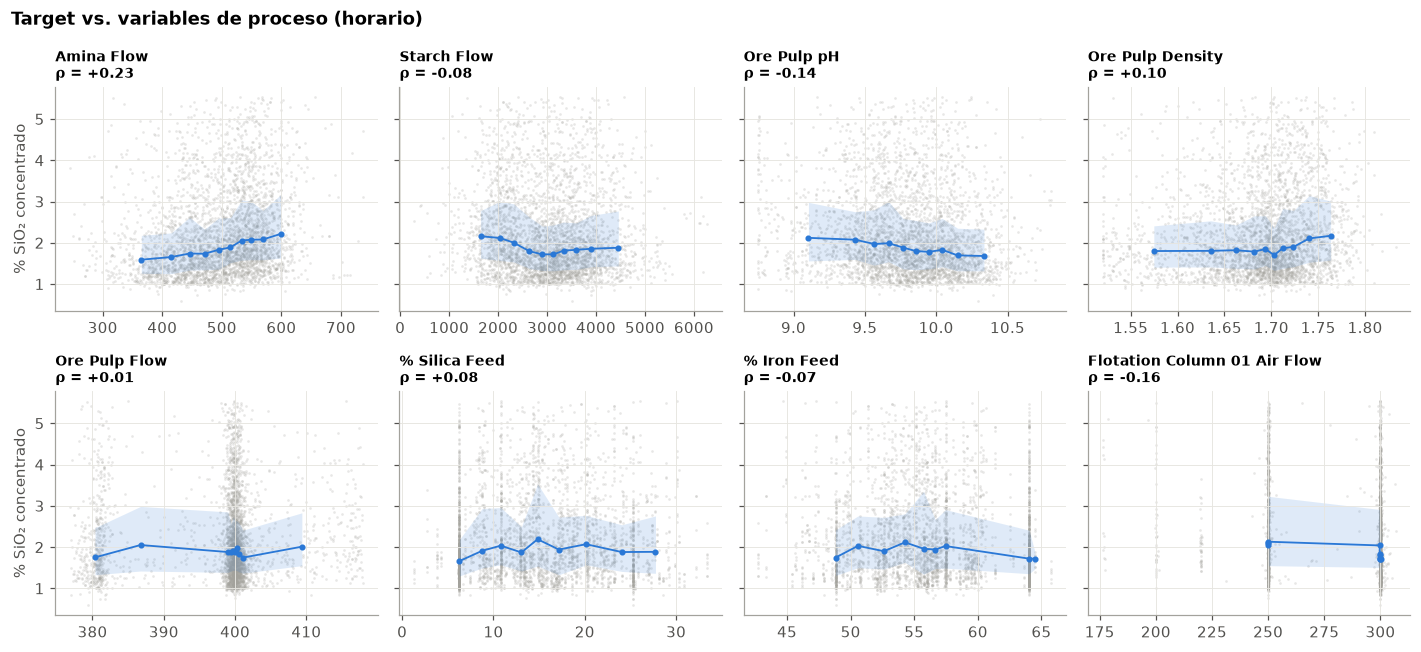

In [21]:
process_vars = ["Amina Flow", "Starch Flow", "Ore Pulp pH", "Ore Pulp Density",
                "Ore Pulp Flow", "% Silica Feed", "% Iron Feed", "Flotation Column 01 Air Flow"]

fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=True)
for ax, col in zip(axes.flat, process_vars):
    x = hourly[col]
    ax.scatter(x, y, s=3, color=GRAY, alpha=0.25, lw=0)
    prof = binned_profile(x, y)
    ax.fill_between(prof["x"], prof["y_q25"], prof["y_q75"], color=BLUE, alpha=0.15, lw=0)
    ax.plot(prof["x"], prof["y_med"], color=BLUE, marker="o", ms=3)
    rho = y.corr(x, method="spearman")
    ax.set_title(f"{col}\nρ = {rho:+.2f}", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("% SiO₂ concentrado")
fig.suptitle("Target vs. variables de proceso (horario)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "02_relaciones_proceso")
plt.show()

### 8a. Aire y nivel de las 7 columnas

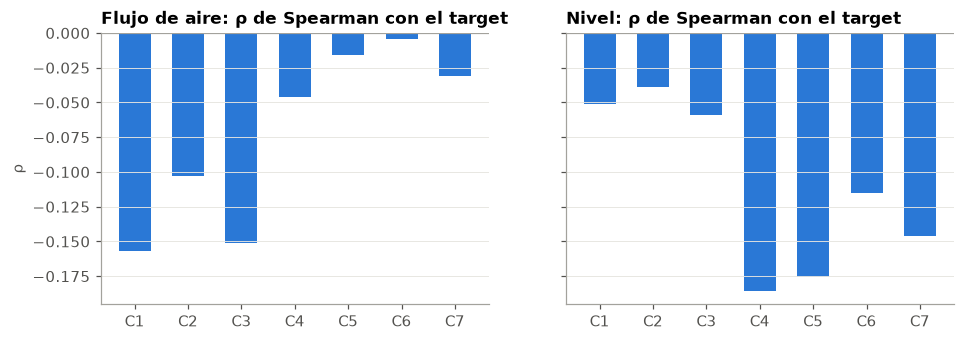

In [22]:
air_cols = [f"Flotation Column {i:02d} Air Flow" for i in range(1, 8)]
level_cols = [f"Flotation Column {i:02d} Level" for i in range(1, 8)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, cols, name in [(axes[0], air_cols, "Flujo de aire"), (axes[1], level_cols, "Nivel")]:
    rhos = [y.corr(hourly[c], method="spearman") for c in cols]
    ax.bar([f"C{i}" for i in range(1, 8)], rhos, color=BLUE, width=0.6)
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.set_title(f"{name}: ρ de Spearman con el target")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("ρ")
save(fig, "02_aire_nivel_columnas")
plt.show()

## 9. Correlaciones

**Correlación no implica causalidad.** En una planta operada, muchas variables de proceso son
*acciones de control*: los operadores las ajustan en respuesta a la calidad observada. Una
correlación puede reflejar esa reacción y no un efecto físico de la variable sobre la sílice.

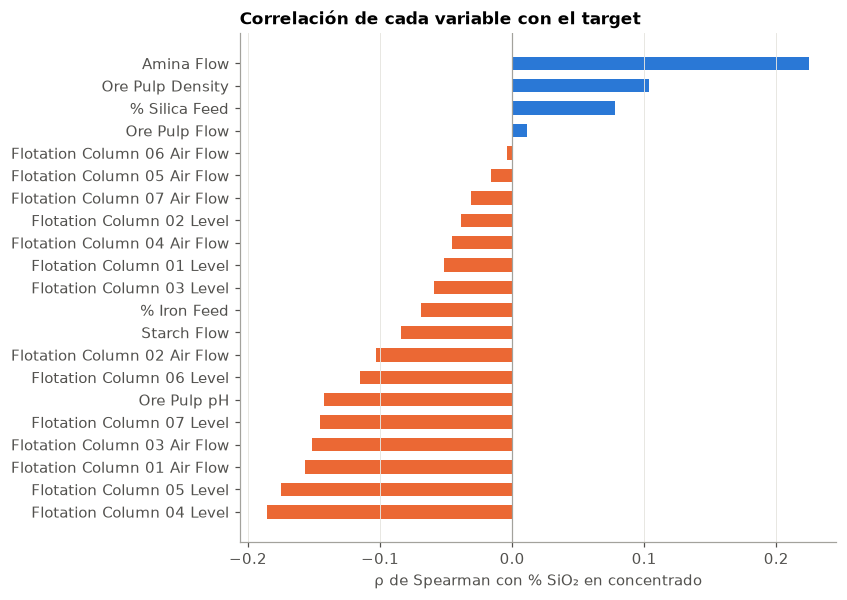

,rho
Flotation Column 04 Level,-0.186
Flotation Column 05 Level,-0.175
Flotation Column 01 Air Flow,-0.157
Flotation Column 03 Air Flow,-0.151
Flotation Column 07 Level,-0.146
Ore Pulp pH,-0.142
Flotation Column 06 Level,-0.115
Flotation Column 02 Air Flow,-0.103
Starch Flow,-0.084
% Iron Feed,-0.069


In [23]:
feature_cols = [c for c in hourly.columns if c not in (TARGET, "% Iron Concentrate", "target_valido")]
rho_target = hourly[feature_cols].corrwith(y, method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
colors = [ORANGE if r < 0 else BLUE for r in rho_target]
ax.barh(rho_target.index, rho_target, color=colors, height=0.6)
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_xlabel("ρ de Spearman con % SiO₂ en concentrado")
ax.set_title("Correlación de cada variable con el target")
ax.grid(axis="y", visible=False)
save(fig, "02_correlacion_target")
plt.show()
rho_target.round(3).to_frame("rho")

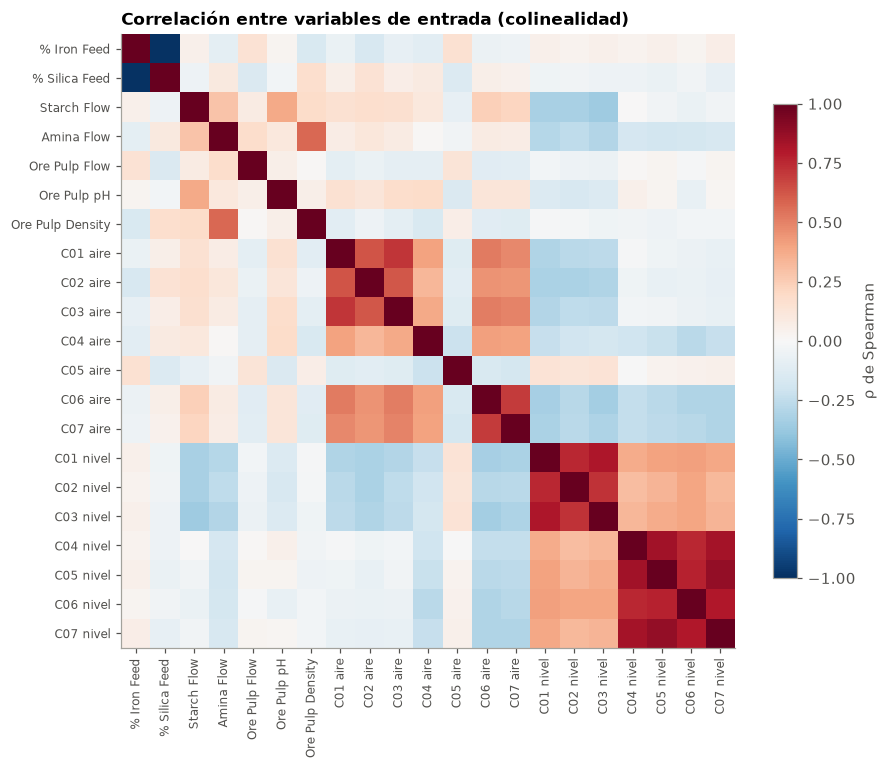

In [24]:
corr = hourly[feature_cols].corr(method="spearman")
short = {c: c.replace("Flotation Column ", "C").replace(" Air Flow", " aire").replace(" Level", " nivel")
         for c in feature_cols}

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), [short[c] for c in corr.columns], rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), [short[c] for c in corr.index], fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
ax.set_title("Correlación entre variables de entrada (colinealidad)")
save(fig, "02_correlacion_entradas")
plt.show()

In [25]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pares más correlacionados entre sí:")
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(2)

Pares más correlacionados entre sí:


% Iron Feed                % Silica Feed               -0.98
Flotation Column 05 Level  Flotation Column 07 Level    0.88
Flotation Column 04 Level  Flotation Column 05 Level    0.84
                           Flotation Column 07 Level    0.83
Flotation Column 01 Level  Flotation Column 03 Level    0.81
Flotation Column 06 Level  Flotation Column 07 Level    0.80
Flotation Column 05 Level  Flotation Column 06 Level    0.77
Flotation Column 04 Level  Flotation Column 06 Level    0.75
dtype: float64

### 9a. ¿Causa o reacción? Correlación con desfase

Calculamos ρ entre la sílice en *t* y cada variable en *t + k*:
- **k < 0**: la variable *antecede* a la sílice (compatible con un efecto físico, tiempo de residencia).
- **k > 0**: la variable *sigue* a la sílice (compatible con una reacción del operador o del control).

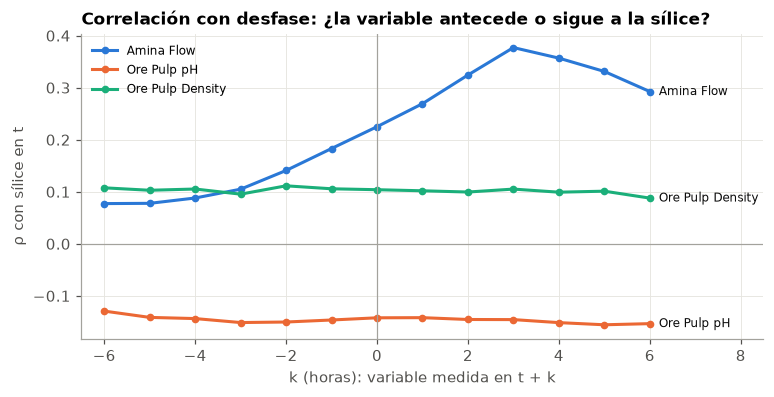

,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6
Amina Flow,0.077,0.078,0.088,0.105,0.141,0.183,0.225,0.269,0.324,0.377,0.357,0.331,0.293
Ore Pulp pH,-0.129,-0.141,-0.144,-0.151,-0.150,-0.146,-0.142,-0.142,-0.145,-0.146,-0.151,-0.156,-0.153
Ore Pulp Density,0.108,0.103,0.105,0.095,0.111,0.106,0.104,0.102,0.100,0.105,0.099,0.101,0.088


In [26]:
lags = range(-6, 7)
lead_lag = pd.DataFrame({c: lagged_spearman(y, hourly[c], lags)
                         for c in ["Amina Flow", "Ore Pulp pH", "Ore Pulp Density"]})

fig, ax = plt.subplots(figsize=(8, 3.6))
for col, color in zip(lead_lag.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(lead_lag.index, lead_lag[col], color=color, marker="o", ms=4, lw=2, label=col)
    ax.text(6.2, lead_lag[col].iloc[-1], col, color=TEXT, va="center", fontsize=8)
ax.axvline(0, color=GRAY, lw=0.8)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xlabel("k (horas): variable medida en t + k")
ax.set_ylabel("ρ con sílice en t")
ax.set_xlim(-6.5, 8.5)
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.set_title("Correlación con desfase: ¿la variable antecede o sigue a la sílice?")
save(fig, "02_desfase_amina")
plt.show()
lead_lag.round(3).T

In [27]:
print("Autocorrelación del target (horas con ensayo real):")
pd.Series({k: y.autocorr(k) for k in range(1, 7)}).round(3).to_frame("acf").T

Autocorrelación del target (horas con ensayo real):


,1,2,3,4,5,6
acf,0.661,0.544,0.457,0.36,0.287,0.252


---
# Parte 3 · Fuga de información: `% Iron Concentrate`

`% Iron Concentrate` y `% Silica Concentrate` salen **del mismo ensayo de laboratorio**, sobre la misma
muestra y en el mismo momento. En operación, cuando se quiere estimar la sílice de la hora actual,
el hierro de esa hora **todavía no existe**. Si existiera, también tendríamos la sílice y no haría
falta predecirla. Usarlo como feature es usar información del futuro.

Además, están ligados por un balance de masa: el concentrado es casi solo Fe₂O₃ + SiO₂ + otros óxidos.
Como Fe = 0,6994·Fe₂O₃ → **SiO₂ ≈ 100 − Fe/0,6994 − otros**.

In [28]:
data = hourly[hourly["target_valido"]].dropna()
iron = data[LEAKY_COLUMNS[0]]
other_oxides = 100 - iron / 0.6994 - data[TARGET]
print(f"Pearson Fe conc vs SiO2 conc: {iron.corr(data[TARGET]):.3f}")
print(f"'Otros óxidos' implícitos (100 − Fe₂O₃ − SiO₂): media {other_oxides.mean():.2f} %, "
      f"desv. est. {other_oxides.std():.2f} pp")
print(f"Correlación 'otros óxidos' vs Fe conc: {other_oxides.corr(iron):.3f}")
print("Pendiente esperada si 'otros' fuera constante: -1/0.6994 =", round(-1 / 0.6994, 2))

Pearson Fe conc vs SiO2 conc: -0.763
'Otros óxidos' implícitos (100 − Fe₂O₃ − SiO₂): media 4.57 %, desv. est. 0.93 pp
Correlación 'otros óxidos' vs Fe conc: -0.698
Pendiente esperada si 'otros' fuera constante: -1/0.6994 = -1.43


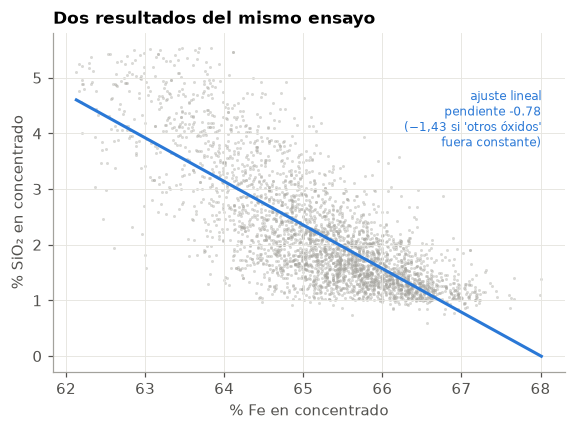

In [29]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(iron, data[TARGET], s=4, color=GRAY, alpha=0.4, lw=0)
slope, intercept = np.polyfit(iron, data[TARGET], 1)
fe_grid = np.linspace(iron.min(), iron.max(), 50)
ax.plot(fe_grid, intercept + slope * fe_grid, color=BLUE, lw=2)
ax.text(fe_grid[-1], 4.8, f"ajuste lineal\npendiente {slope:.2f}\n(−1,43 si 'otros óxidos'\nfuera constante)",
        color=BLUE, fontsize=8, ha="right", va="top")
ax.set_xlabel("% Fe en concentrado")
ax.set_ylabel("% SiO₂ en concentrado")
ax.set_title("Dos resultados del mismo ensayo")
save(fig, "03_fuga_balance_masa")
plt.show()

### Experimento: ¿cuánto "mejora" un modelo si le damos `% Iron Concentrate`?

Split **temporal** (entrena antes de `TEST_START`, evalúa después) y Ridge con escalado. Usamos
features de proceso contemporáneas, sin rezagos: el objetivo aquí es aislar el efecto de la columna
con fuga, no construir el modelo final (ver `02_modelo`). XGBoost se reporta como contraste.

In [30]:
process_cols = [c for c in hourly.columns if c not in (TARGET, "target_valido", *LEAKY_COLUMNS)]
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
print(f"Train: {len(train)} h ({train.index.min():%Y-%m-%d} → {train.index.max():%Y-%m-%d}) | "
      f"Test: {len(test)} h ({test.index.min():%Y-%m-%d} → {test.index.max():%Y-%m-%d})")

feature_sets = {
    "Proceso": process_cols,
    "Solo % Iron Conc.": LEAKY_COLUMNS,
    "Proceso + % Iron Conc.": process_cols + LEAKY_COLUMNS,
}
results = {"Media de train (baseline)": regression_metrics(test[TARGET], np.full(len(test), train[TARGET].mean()))}
results_xgb = {}
for name, cols in feature_sets.items():
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(train[cols], train[TARGET])
    results[name] = regression_metrics(test[TARGET], ridge.predict(test[cols]))
    xgb = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=SEED)
    xgb.fit(train[cols], train[TARGET])
    results_xgb[name] = regression_metrics(test[TARGET], xgb.predict(test[cols]))

leak_table = pd.DataFrame(results).T
leak_table["mejora_vs_media"] = leak_table["MAE"].apply(
    lambda m: relative_improvement(m, leak_table.loc["Media de train (baseline)", "MAE"]))
leak_table["MAE_xgb"] = pd.Series({k: v["MAE"] for k, v in results_xgb.items()})
leak_table.round(3)

Train: 2610 h (2017-03-10 → 2017-07-31) | Test: 752 h (2017-08-03 → 2017-09-09)


,MAE,RMSE,R2,mejora_vs_media,MAE_xgb
Media de train (baseline),0.828,1.054,-0.001,0.000,NaN
Proceso,0.865,1.164,-0.220,-0.045,0.862
Solo % Iron Conc.,0.590,0.720,0.533,0.288,0.560
Proceso + % Iron Conc.,0.528,0.664,0.603,0.362,0.673


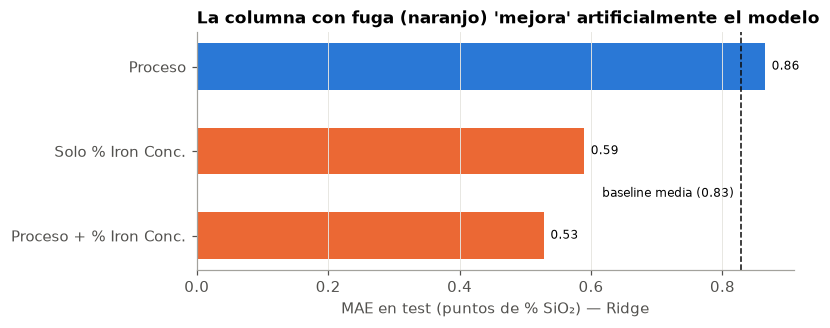

In [31]:
fig, ax = plt.subplots(figsize=(7, 2.8))
order = ["Proceso", "Solo % Iron Conc.", "Proceso + % Iron Conc."]
colors = [BLUE, ORANGE, ORANGE]
ax.barh(order, leak_table.loc[order, "MAE"], color=colors, height=0.55)
baseline_mae = leak_table.loc["Media de train (baseline)", "MAE"]
ax.axvline(baseline_mae, color=TEXT, lw=1, ls="--")
ax.text(baseline_mae - 0.01, 1.5, f"baseline media ({baseline_mae:.2f})", fontsize=8, va="center", ha="right")
for i, name in enumerate(order):
    ax.text(leak_table.loc[name, "MAE"] + 0.01, i, f"{leak_table.loc[name, 'MAE']:.2f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("MAE en test (puntos de % SiO₂) — Ridge")
ax.set_title("La columna con fuga (naranjo) 'mejora' artificialmente el modelo")
ax.grid(axis="y", visible=False)
save(fig, "03_fuga_mae")
plt.show()

In [32]:
iron_interp = df.groupby("date")[LEAKY_COLUMNS[0]].nunique() > 1
print("Horas con % Iron Conc. interpolado:", int(iron_interp.sum()),
      "| de ellas, también con sílice interpolada:", int((iron_interp & flags["target_interpolado"]).sum()))

Horas con % Iron Conc. interpolado: 216 | de ellas, también con sílice interpolada: 206


**Decisión:** `% Iron Concentrate` se excluye de todo lo que sigue (`LEAKY_COLUMNS` en `src/config.py`).

## 11. Guardar para los siguientes notebooks

In [33]:
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
df.to_parquet(DATA_PROCESSED / "raw.parquet", index=False)
flags.to_parquet(DATA_PROCESSED / "flags_horarios.parquet")
print("Guardado en data/processed/")

Guardado en data/processed/
